# モジュール 6 発展版：複数ドナーデータによる擬似バルク差次発現解析

本編（`sc-rna-seq.ipynb`）のモジュール 6 では，単一ドナーの PBMC 3k を無作為に分けた仮サンプルで，擬似バルクの集約 $Y = AX$ を計算するところまでを行った．本ノートブックでは，**生物学的反復（ドナー）と条件を持つ実データ** で，

1. ドナー × 条件 × 細胞型ごとの擬似バルク行列を作り，
2. 負の二項一般化線形モデル（DESeq2 の Python 実装 PyDESeq2）で条件間の差次発現を検定し，
3. 細胞単位の Wilcoxon 検定（擬似反復）と比べて，偽陽性の出方を実験で確かめる．

**データ**：Kang et al. (2018) の PBMC データ．全身性エリテマトーデス（ループス）患者 8 名の PBMC を，それぞれ未処置（`ctrl`）とインターフェロン β（IFN-β）刺激（`stim`）の 2 条件に分けて測定したもの．同一ドナーの `ctrl` / `stim` が対になる **対応のある設計** である．細胞型ラベル（`cell_type`）は配布元の注釈をそのまま用いる．

データの取得（`course/` で実行）：

```bash
curl -L https://exampledata.scverse.org/pertpy/kang_2018.h5ad -o data/kang_2018.h5ad
```

PyDESeq2 は依存グループ `multidonor` に入っており，既定の `uv sync` では入らない．リポジトリ直下で `uv run --group multidonor jupyter lab course/module6-multidonor.ipynb` と起動する．

## 1. 読み込みと確認

In [1]:
import itertools
import warnings

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

adata = sc.read_h5ad('data/kang_2018.h5ad')
print(adata)

# X が非負整数値の生カウントであることを確認する
assert adata.X.data.min() >= 0 and np.array_equal(adata.X.data, np.round(adata.X.data))

# ドナー × 条件 × 細胞型ごとの細胞数
pd.crosstab([adata.obs['replicate'], adata.obs['label']], adata.obs['cell_type'])

AnnData object with n_obs × n_vars = 24673 × 15706
    obs: 'nCount_RNA', 'nFeature_RNA', 'tsne1', 'tsne2', 'label', 'cluster', 'cell_type', 'replicate', 'nCount_SCT', 'nFeature_SCT', 'integrated_snn_res.0.4', 'seurat_clusters'
    var: 'name'
    obsm: 'X_pca', 'X_umap'


cell_type           CD4 T cells  CD14+ Monocytes  B cells  NK cells  \
replicate    label                                                    
patient_101  ctrl           353              207      106        65   
             stim           467              269      141        84   
patient_107  ctrl           180              210       44        37   
             stim           199              179       60        40   
patient_1015 ctrl           951              859      459       179   
             stim           835              718      366       175   
patient_1016 ctrl           502              393      125        90   
             stim           461              355      123        98   
patient_1039 ctrl           201              126       26        21   
             stim           302              164       41        22   
patient_1244 ctrl          1108              418      118       102   
             stim           892              300       96       107   
patient_1256 ctrl          1049              402      218       242   
             stim           993              387      219       186   
patient_1488 ctrl          1216              317      220       119   
             stim          1529              393      289       149   

cell_type           CD8 T cells  FCGR3A+ Monocytes  Dendritic cells  \
replicate    label                                                    
patient_101  ctrl            29                 72               25   
             stim            54                112               39   
patient_107  ctrl             8                 24               14   
             stim            10                 20               16   
patient_1015 ctrl            85                164               40   
             stim            60                159               36   
patient_1016 ctrl           504                 81               27   
             stim           489                 89               20   
patient_1039 ctrl             9                 15               10   
             stim            11                 25               18   
patient_1244 ctrl            29                 41               62   
             stim            12                 17               37   
patient_1256 ctrl           114                 47               34   
             stim           132                 57               48   
patient_1488 ctrl            33                 76               46   
             stim            42                 90               57   

cell_type           Megakaryocytes  
replicate    label                  
patient_101  ctrl                1  
             stim                0  
patient_107  ctrl                0  
             stim                1  
patient_1015 ctrl                1  
             stim                3  
patient_1016 ctrl                1  
             stim                0  
patient_1039 ctrl               53  
             stim               58  
patient_1244 ctrl                1  
             stim                3  
patient_1256 ctrl                2  
             stim                4  
patient_1488 ctrl                4  
             stim                0

In [2]:
# 最小限の QC（sc-best-practices の章と同じ閾値）
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
print(adata.shape)

(24562, 15701)


## 2. 擬似バルク化

本編モジュール 6 と同じく，細胞 $i$ の属するグループを $g(i)$ とし，所属行列 $A \in \{0,1\}^{G \times n}$ を $A_{gi} = \mathbf{1}[g(i) = g]$ で定めると，擬似バルク行列は

$$Y = AX \in \mathbb{Z}_{\geq 0}^{G \times m}, \qquad Y_{gj} = \sum_{i : g(i) = g} X_{ij}$$

である．ここではグループを（ドナー，条件，細胞型）の 3 つ組とする．実装には，本編で $A$ による計算との一致を確かめた `sc.get.aggregate` を使う．

細胞数の少ないグループは推定が不安定なので除外する．sc-best-practices の章にならい，**細胞数 10 未満，または総カウント 1000 未満** のグループを除く．

In [3]:
pb = sc.get.aggregate(adata, by=['replicate', 'label', 'cell_type'], func='sum')
pb.X = pb.layers['sum']

# 検算：擬似バルクの総和は元のカウントの総和に一致する
assert np.isclose(pb.X.sum(), adata.X.sum())

pb.obs['n_cells'] = pb.obs['n_obs_aggregated']
pb.obs['total_counts'] = np.asarray(pb.X.sum(axis=1)).ravel()
print(f'グループ数（0 細胞のグループは作られない）: {pb.n_obs}')

keep = (pb.obs['n_cells'] >= 10) & (pb.obs['total_counts'] >= 1000)
print('除外するグループ:')
print(pb.obs.loc[~keep, ['replicate', 'label', 'cell_type', 'n_cells', 'total_counts']].to_string())
pb = pb[keep].copy()
print(f'残るグループ数: {pb.n_obs}')

グループ数（0 細胞のグループは作られない）: 123
除外するグループ:
                                     replicate label       cell_type  n_cells  total_counts
patient_101_ctrl_Megakaryocytes    patient_101  ctrl  Megakaryocytes        1        3565.0
patient_107_ctrl_CD8 T cells       patient_107  ctrl     CD8 T cells        8        7227.0
patient_107_stim_Megakaryocytes    patient_107  stim  Megakaryocytes        1        5543.0
patient_1015_ctrl_Megakaryocytes  patient_1015  ctrl  Megakaryocytes        1        4312.0
patient_1015_stim_Megakaryocytes  patient_1015  stim  Megakaryocytes        3       13268.0
patient_1016_ctrl_Megakaryocytes  patient_1016  ctrl  Megakaryocytes        1        5759.0
patient_1039_ctrl_CD8 T cells     patient_1039  ctrl     CD8 T cells        9        8190.0
patient_1039_stim_Megakaryocytes  patient_1039  stim  Megakaryocytes        1        4225.0
patient_1244_ctrl_Megakaryocytes  patient_1244  ctrl  Megakaryocytes        1        4176.0
patient_1244_stim_Megakaryocytes  patient_

## 3. 探索：擬似バルクの PCA

擬似バルクを CPM（100 万カウントあたり）に正規化し， $\log(1 + x)$ 変換と標準化の後に PCA を行う．サンプル間のばらつきの主な要因（細胞型，条件，ドナー）を見る．

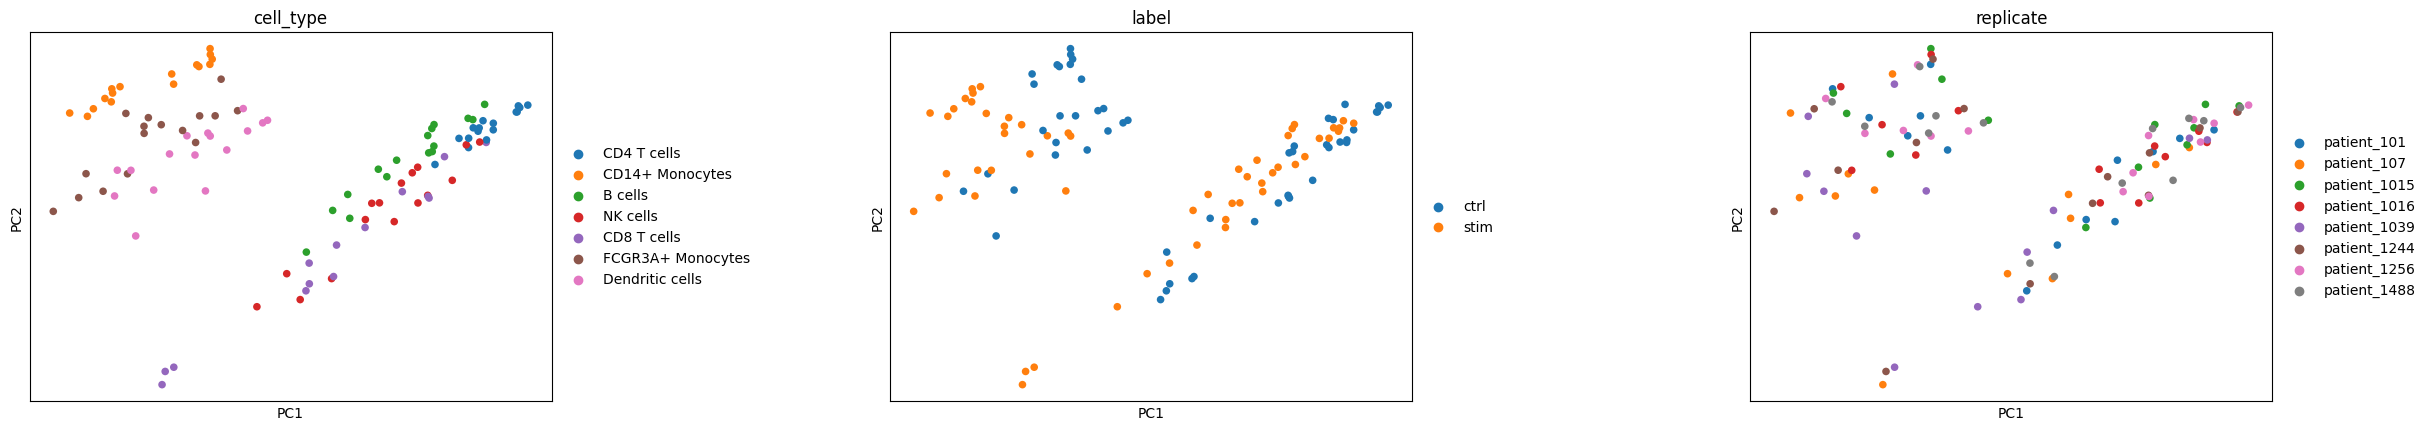

In [4]:
pb_vis = pb.copy()
sc.pp.normalize_total(pb_vis, target_sum=1e6)
sc.pp.log1p(pb_vis)
sc.pp.scale(pb_vis, max_value=10)
sc.tl.pca(pb_vis)
sc.pl.pca(pb_vis, color=['cell_type', 'label', 'replicate'], size=120, ncols=3, wspace=0.5)

図では，骨髄系（単球，樹状細胞）とリンパ球系（T，B，NK）が 2 つの塊に分かれ，条件（`label`）の違いは各細胞型の内側に現れる．以下では， **CD14+ 単球**（`CD14+ Monocytes`）に絞って解析する（sc-best-practices の章によれば，元論文で最も多くの差次発現遺伝子が見つかった細胞型である）．

## 4. 負の二項一般化線形モデル（DESeq2）

CD14+ 単球の擬似バルクサンプル $g = 1, \dots, G$ （ここでは $G = 16$ ）と遺伝子 $j$ について，

$$Y_{gj} \sim \mathrm{NB}(\mu_{gj}, \alpha_j), \qquad \mathbb{E}[Y_{gj}] = \mu_{gj}, \qquad \mathrm{Var}(Y_{gj}) = \mu_{gj} + \alpha_j \mu_{gj}^2,$$

$$\log \mu_{gj} = \log s_g + \mathbf{x}_g^\top \boldsymbol{\beta}_j$$

とおく． $s_g$ はサイズ因子（ライブラリサイズの補正）， $\alpha_j$ は遺伝子ごとの分散パラメータ（ $\alpha_j \to 0$ でポアソン分布）， $\mathbf{x}_g$ は計画行列の行， $\boldsymbol{\beta}_j$ は回帰係数である．

**計画行列**：対応のある設計 `~ replicate + label` では

$$\mathbf{x}_g^\top \boldsymbol{\beta}_j = \beta_{j,0} + \sum_{d=2}^{8} \beta_{j,d}\, \mathbf{1}[\text{donor}(g) = d] + \beta_{j,\mathrm{stim}}\, \mathbf{1}[\text{label}(g) = \mathrm{stim}]$$

（ドナー 1 と `ctrl` が基準）．ドナー効果を固定効果として除いたうえで，条件効果 $\beta_{j,\mathrm{stim}}$ を検定する．帰無仮説は $H_0 : \beta_{j,\mathrm{stim}} = 0$ ．log fold change は $\beta_{j,\mathrm{stim}} / \log 2$ である．

DESeq2（Love, Huber & Anders 2014）の推定は次の段階からなる．

1. **サイズ因子**（median-of-ratios）：遺伝子ごとの幾何平均 $K_j = \bigl(\prod_{g} Y_{gj}\bigr)^{1/G}$ を参照とし，
   $$s_g = \operatorname*{median}_{j : K_j > 0} \frac{Y_{gj}}{K_j}.$$
   少数の遺伝子の大きな変化に頑健な正規化である．
2. **遺伝子ごとの分散推定**：各遺伝子で $\alpha_j$ を（Cox–Reid 補正付きの）最尤法で推定する．サンプル数 $G$ が小さいので推定値の分散は大きい．
3. **分散のトレンドと縮小**：遺伝子をまたいで平均 $\bar{\mu}_j$ と分散の関係（トレンド） $\alpha_{\mathrm{tr}}(\bar{\mu})$ を当てはめ，対数分散に正規事前分布 $\log \alpha_j \sim \mathcal{N}(\log \alpha_{\mathrm{tr}}(\bar{\mu}_j), \sigma_d^2)$ をおいて MAP 推定する（経験ベイズ的な縮小）．DESeq2 の標準のトレンドはパラメトリックな $\alpha_{\mathrm{tr}}(\bar{\mu}) = a_0 + a_1 / \bar{\mu}$ である．
4. **係数の推定と Wald 検定**：分散を固定して $\boldsymbol{\beta}_j$ を IRLS で最尤推定し，
   $$W_j = \frac{\hat{\beta}_{j,\mathrm{stim}}}{\widehat{\mathrm{SE}}(\hat{\beta}_{j,\mathrm{stim}})}$$
   を標準正規分布と比べて $p$ 値を得る．
5. **多重検定補正**：Benjamini–Hochberg 法で調整済み $p$ 値（`padj`）を求める．DESeq2 は既定で，平均発現の低い遺伝子を除く独立フィルタリングと，Cook の距離による外れ値処理も行う．

**本ノートブックでの注意**：このデータでは，パラメトリックなトレンドの当てはめが，遺伝子フィルタの閾値によって収束したりしなかったりする（収束しないと，PyDESeq2 は警告を出して平均値によるトレンドに切り替える）．結果が閾値に左右されないよう，最初から `fit_type='mean'` を指定し，トレンドを定数（遺伝子ごとの分散推定値の刈り込み平均）とする．これは標準の DESeq2 からの変更であり，影響は第 5 節の図の後で述べる．

### 遺伝子のフィルタ

発現の低い遺伝子は検定力がなく，分散推定も不安定なので，あらかじめ除く．edgeR の `filterByExpr` にならい，サンプル $g$ のライブラリサイズを $L_g = \sum_j Y_{gj}$ ，その中央値を $\tilde{L}$ として，

$$\mathrm{CPM}_{gj} = 10^6 \, \frac{Y_{gj}}{L_g}, \qquad \text{遺伝子 } j \text{ を残す} \iff \#\{ g : \mathrm{CPM}_{gj} \geq 10^7 / \tilde{L} \} \geq 8 \ \text{かつ} \ \sum_g Y_{gj} \geq 15$$

とする．閾値 $10^7 / \tilde{L}$ は「中央値のライブラリサイズで 10 カウントに相当する CPM」，8 は小さい方の群（各条件 8 サンプル）の大きさである．

In [5]:
mono = pb[pb.obs['cell_type'] == 'CD14+ Monocytes'].copy()
mono.obs_names = [f'{r}_{l}' for r, l in zip(mono.obs['replicate'], mono.obs['label'])]

counts = pd.DataFrame(mono.X.astype(int), index=mono.obs_names, columns=mono.var_names)
metadata = mono.obs[['replicate', 'label']].astype(str)
assert len(counts) == 16  # 8 ドナー × 2 条件がすべて残っている

lib = counts.sum(axis=1)
cpm = counts.div(lib, axis=0) * 1e6
cpm_cutoff = 10 / lib.median() * 1e6
keep_genes = ((cpm >= cpm_cutoff).sum(axis=0) >= 8) & (counts.sum(axis=0) >= 15)
counts = counts.loc[:, keep_genes]
print(f'CPM の閾値: {cpm_cutoff:.2f}')
print(f'残る遺伝子数: {counts.shape[1]} / {keep_genes.size}')

CPM の閾値: 13.55
残る遺伝子数: 3709 / 15701


## 5. PyDESeq2 による検定（対応のある設計）

In [6]:
inference = DefaultInference(n_cpus=4)

def run_deseq2(counts, metadata, design, contrast):
    # PyDESeq2 を実行し，(DeseqDataSet, 結果の DataFrame) を返す
    dds = DeseqDataSet(counts=counts, metadata=metadata, design=design,
                       fit_type='mean', inference=inference, quiet=True)
    dds.deseq2()
    stats = DeseqStats(dds, contrast=contrast, inference=inference, quiet=True)
    stats.summary()
    return dds, stats.results_df

dds, res = run_deseq2(counts, metadata, '~ replicate + label', ['label', 'stim', 'ctrl'])

# サイズ因子を median-of-ratios の定義から直接計算して照合する
with np.errstate(divide='ignore'):            # カウント 0 の log は -inf（下で除く）
    logY = np.log(counts.values.astype(float))
logK = logY.mean(axis=0)                     # log 幾何平均
ok = np.isfinite(logK)                       # 全サンプルで正の遺伝子のみ
s_manual = np.exp(np.median(logY[:, ok] - logK[ok], axis=1))
assert np.allclose(s_manual, dds.obs['size_factors'].values)
print(pd.Series(s_manual, index=counts.index, name='size factor').round(3).to_string())

patient_101_ctrl     0.919
patient_101_stim     1.023
patient_107_ctrl     0.730
patient_107_stim     0.514
patient_1015_ctrl    2.978
patient_1015_stim    2.104
patient_1016_ctrl    1.258
patient_1016_stim    0.973
patient_1039_ctrl    0.480
patient_1039_stim    0.530
patient_1244_ctrl    1.561
patient_1244_stim    0.819
patient_1256_ctrl    1.583
patient_1256_stim    1.173
patient_1488_ctrl    0.890
patient_1488_stim    0.954


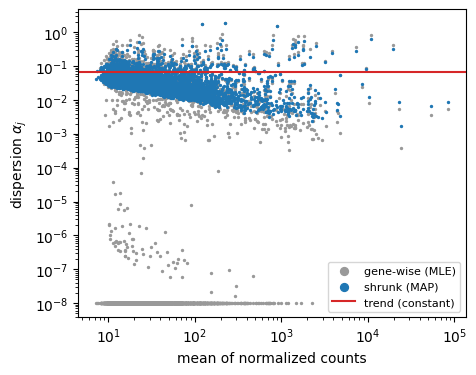

遺伝子ごとの推定値が下限（1e-8）付近にある遺伝子の割合: 0.60


In [7]:
# 分散の推定：遺伝子ごとの推定値，トレンド（ここでは定数），縮小後の値
fig, ax = plt.subplots(figsize=(5, 4))
mean_norm = dds.layers['normed_counts'].mean(axis=0)
ax.scatter(mean_norm, dds.var['genewise_dispersions'], s=2, c='0.6', label='gene-wise (MLE)')
ax.scatter(mean_norm, dds.var['dispersions'], s=2, c='C0', label='shrunk (MAP)')
ax.axhline(dds.var['fitted_dispersions'].iloc[0], c='C3', label='trend (constant)')
ax.set(xscale='log', yscale='log', xlabel='mean of normalized counts', ylabel=r'dispersion $\alpha_j$')
ax.legend(markerscale=4, fontsize=8)
plt.show()

floor_frac = (dds.var['genewise_dispersions'] <= 1e-7).mean()
print(f'遺伝子ごとの推定値が下限（1e-8）付近にある遺伝子の割合: {floor_frac:.2f}')

図の読み方は次のとおりである．

- 遺伝子ごとの最尤推定値（灰色）の多くが，推定の下限 $10^{-8}$ に張り付いている．サンプルが少ないと，カウントのばらつきがポアソン分布の範囲に収まって見える遺伝子では $\hat{\alpha}_j$ が 0 側に行くからであり，これが縮小を必要とする理由である．
- 縮小後の値（青）は平均とともに減少する．定数のトレンド（赤）はこの平均依存性を表せない．この点でモデルは粗い．

**感度の確認**：`fit_type` と遺伝子フィルタを変えて別途実行し，結論が変わらないことを確かめた（下の表）．有意な遺伝子数は残す遺伝子数とともに変わるが，第 6 節 (b) の偽陽性の傾向はほとんど変わらない．

| 遺伝子フィルタ（中央値のライブラリサイズでのカウント） | `fit_type` | 検定した遺伝子数 | 有意な遺伝子数（ `stim` 対 `ctrl` ） | 帰無実験で偽陽性が出た分け方 | 偽陽性数の平均 | 偽陽性数の最大 |
|---|---|---:|---:|---:|---:|---:|
| 10（本ノートブック） | `mean` | 3709 | 2418 | 8 / 35 | 1.2 | 24 |
| 3 | `parametric` | 6374 | 3178 | 9 / 35 | 1.7 | 23 |
| 3 | `mean` | 6374 | 3302 | 10 / 35 | 1.1 | 23 |

In [8]:
alpha = 0.05
n_sig_paired = int((res['padj'] < alpha).sum())
print(f'有意な遺伝子数（padj < {alpha}）: {n_sig_paired} / {len(res)}')
print(res.sort_values('padj').head(15)[['baseMean', 'log2FoldChange', 'lfcSE', 'padj']].to_string())

# インターフェロン応答遺伝子（ISG）の例
isg = ['ISG15', 'IFIT1', 'IFIT3', 'MX1', 'IFI6', 'OAS1']
print(res.loc[[g for g in isg if g in res.index], ['log2FoldChange', 'padj']].to_string())

有意な遺伝子数（padj < 0.05）: 2418 / 3709
            baseMean  log2FoldChange     lfcSE           padj
index                                                        
H3F3B    4806.722916        1.106617  0.043571  9.909419e-139
IL1RN     912.144327        6.682121  0.267073  6.904108e-135
CCL8     7361.337962        9.819712  0.406396  5.857520e-126
DYNLT1    955.298586        2.687201  0.111239  5.857520e-126
TMSB10   2667.722637        2.201822  0.093235  1.967397e-120
MYL12A   1233.774556        1.928389  0.082261  9.755031e-119
NAGK      240.126642        2.418835  0.104868  5.437201e-115
IFITM2    497.878952        4.794641  0.210099  1.318646e-112
HSPB1     680.099666        3.048028  0.134733  1.065674e-110
SSB       369.613334        3.413369  0.151743  1.745325e-109
ISG20    3165.016165        5.695705  0.263325  3.168158e-101
TMEM50A   378.293667        1.722370  0.079670  3.700679e-101
IRF7      711.389378        3.434014  0.163052   5.195292e-96
PLEK      402.961047        2.106523

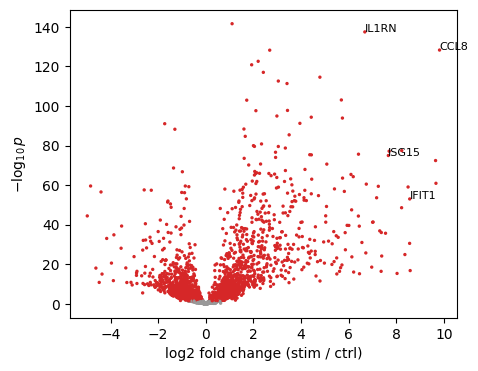

In [9]:
# volcano plot
fig, ax = plt.subplots(figsize=(5, 4))
sig = res['padj'] < alpha
ax.scatter(res['log2FoldChange'], -np.log10(res['pvalue']), s=2, c=np.where(sig, 'C3', '0.6'))
for g in ['ISG15', 'IFIT1', 'CCL8', 'IL1RN']:
    if g in res.index:
        ax.annotate(g, (res.loc[g, 'log2FoldChange'], -np.log10(res.loc[g, 'pvalue'])), fontsize=8)
ax.set(xlabel='log2 fold change (stim / ctrl)', ylabel=r'$-\log_{10} p$')
plt.show()

### 対応のない設計との比較

ドナー効果を入れない `~ label`（sc-best-practices の章の計画式）でも推定し，有意遺伝子数を比べる．対応のある設計では，ドナー間の差が残差から除かれるので，一般に検出力が上がる．ただしその代償として自由度が 7 減る（ $16 - 2 = 14$ から $16 - 9 = 7$ へ）．

In [10]:
_, res_unpaired = run_deseq2(counts, metadata, '~ label', ['label', 'stim', 'ctrl'])
n_sig_unpaired = int((res_unpaired['padj'] < alpha).sum())
both = (res['padj'] < alpha) & (res_unpaired['padj'] < alpha)
print(pd.Series({'~ replicate + label': n_sig_paired,
                 '~ label': n_sig_unpaired,
                 '両方で有意': int(both.sum())}, name='有意な遺伝子数').to_string())

~ replicate + label    2418
~ label                2352
両方で有意                  2324


## 6. 擬似反復の実験

### (a) 実データ：細胞単位の Wilcoxon 検定

同じ CD14+ 単球の細胞を 1 つずつ標本とみなし， `stim` 対 `ctrl` を Wilcoxon 順位和検定で比べる（本編モジュール 5・6 と同じ `sc.tl.rank_genes_groups`）．遺伝子は上と同じものに揃える．

In [11]:
cells = adata[adata.obs['cell_type'] == 'CD14+ Monocytes', counts.columns].copy()
sc.pp.normalize_total(cells, target_sum=1e4)
sc.pp.log1p(cells)

sc.tl.rank_genes_groups(cells, groupby='label', groups=['stim'], reference='ctrl', method='wilcoxon')
wil = sc.get.rank_genes_groups_df(cells, group='stim').set_index('names')
n_sig_wilcoxon = int((wil['pvals_adj'] < alpha).sum())
print(f'細胞数: {cells.n_obs}')
print(f'Wilcoxon で有意な遺伝子数: {n_sig_wilcoxon}')
print(f'擬似バルク（~ replicate + label）で有意な遺伝子数: {n_sig_paired}')

細胞数: 5696
Wilcoxon で有意な遺伝子数: 1995
擬似バルク（~ replicate + label）で有意な遺伝子数: 2418


IFN-β 刺激は非常に強い処置なので，どちらの方法でも検定した遺伝子の過半数が有意になる．細胞単位の検定の方が有意な遺伝子が多いわけではなく，この比較からは優劣を判断できない．問題がはっきり現れるのは **群の間に処置の差がないとき** である．

### (b) 帰無データでの偽陽性

`ctrl` の細胞だけを使い，8 名のドナーを 4 名ずつの仮の群 A，B に分ける．どちらも未処置で，群はドナーの性質と無関係に作ったものなので，群に効果はない．知りたいのは「群がドナーの母集団で差をもたらすか」であり，その答えはすべての遺伝子で「否」だから，有意と判定された遺伝子はこの問いに対する偽陽性である．

8 名を 4 対 4 に分ける方法は $\binom{8}{4} / 2 = 35$ 通り（A と B の入れ替えを同一視）なので，すべての分け方について

- 細胞単位の Wilcoxon 検定（細胞を独立な標本とみなす），
- 擬似バルク＋PyDESeq2（`~ group`，ドナーが標本）

の偽陽性数（ $\mathrm{padj} < 0.05$ の遺伝子数）を数える．

**なぜ差が出るか**：同じドナーの細胞は，遺伝的背景や採血条件を共有するので独立ではない．群 A，B の間には「ドナーの違い」という本物の差があり，細胞単位の検定はそれを条件の差と区別できない．標本数を細胞数（各群で千個前後）と数えるため，ドナー間の小さな差でも有意になる．擬似バルクでは標本はドナー（各群 4）であり，ドナー間のばらつきが分散 $\alpha_j$ に入る．

なお，細胞単位の検定の棄却は「この 4 名の細胞とあの 4 名の細胞では分布が違う」という主張としては誤りとは限らない．検定が答えている問いが，知りたい問い（母集団についての推測）と違うのである．

In [12]:
ctrl_mask = (metadata['label'] == 'ctrl').values
counts_ctrl = counts[ctrl_mask]
meta_ctrl = metadata[ctrl_mask].copy()
cells_ctrl = cells[cells.obs['label'] == 'ctrl'].copy()

donors = sorted(meta_ctrl['replicate'].unique())
rows = []
# donors[0] を常に群 A に入れて，A と B の入れ替えの重複を除く（C(7,3) = 35 通り）
for others in itertools.combinations(donors[1:], 3):
    group_a = {donors[0], *others}

    cells_ctrl.obs['group'] = pd.Categorical(
        np.where(cells_ctrl.obs['replicate'].isin(group_a), 'A', 'B'))
    sc.tl.rank_genes_groups(cells_ctrl, groupby='group', groups=['A'], reference='B',
                            method='wilcoxon')
    fp_wilcoxon = int((sc.get.rank_genes_groups_df(cells_ctrl, group='A')['pvals_adj'] < alpha).sum())

    meta_ctrl['group'] = np.where(meta_ctrl['replicate'].isin(group_a), 'A', 'B')
    _, res_null = run_deseq2(counts_ctrl, meta_ctrl[['group']], '~ group', ['group', 'A', 'B'])
    fp_pseudobulk = int((res_null['padj'] < alpha).sum())

    rows.append({'group A': ', '.join(sorted(d.removeprefix('patient_') for d in group_a)),
                 'Wilcoxon（細胞単位）': fp_wilcoxon,
                 '擬似バルク DESeq2': fp_pseudobulk})

null_df = pd.DataFrame(rows)
print(f'検定した遺伝子数: {counts.shape[1]}，分け方: {len(null_df)} 通り')
null_df.describe().loc[['mean', '50%', 'min', 'max']].round(1)

検定した遺伝子数: 3709，分け方: 35 通り


,Wilcoxon（細胞単位）,擬似バルク DESeq2
mean,153.8,1.2
50%,139.0,0.0
min,74.0,0.0
max,271.0,24.0


                偽陽性 0 個の分け方の数  偽陽性数の中央値  偽陽性数の最大値
Wilcoxon（細胞単位）              0     139.0       271
擬似バルク DESeq2               27       0.0        24
              group A  Wilcoxon（細胞単位）  擬似バルク DESeq2
 101, 107, 1244, 1488             154            24
101, 1015, 1016, 1244             184             5
 101, 1039, 107, 1244             271             4
擬似バルクで偽陽性が 1 個以上出た分け方: 8 / 35 = 0.23


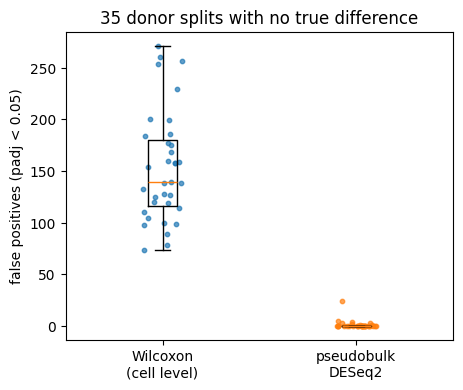

In [13]:
summary = pd.DataFrame({
    '偽陽性 0 個の分け方の数': (null_df.iloc[:, 1:] == 0).sum(),
    '偽陽性数の中央値': null_df.iloc[:, 1:].median(),
    '偽陽性数の最大値': null_df.iloc[:, 1:].max(),
})
print(summary.to_string())
print(null_df.sort_values('擬似バルク DESeq2', ascending=False).head(3).to_string(index=False))

n_any = int((null_df['擬似バルク DESeq2'] > 0).sum())
print(f'擬似バルクで偽陽性が 1 個以上出た分け方: {n_any} / {len(null_df)} = {n_any / len(null_df):.2f}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot([null_df['Wilcoxon（細胞単位）'], null_df['擬似バルク DESeq2']], showfliers=False)
for k, col in enumerate(['Wilcoxon（細胞単位）', '擬似バルク DESeq2'], start=1):
    ax.scatter(np.full(len(null_df), k) + np.random.default_rng(0).uniform(-0.1, 0.1, len(null_df)),
               null_df[col], s=10, alpha=0.7)
ax.set_xticks([1, 2], ['Wilcoxon\n(cell level)', 'pseudobulk\nDESeq2'])
ax.set_ylabel('false positives (padj < 0.05)')
ax.set_title('35 donor splits with no true difference')
plt.show()

## 7. まとめと限界

- 細胞単位の検定は，細胞を独立な標本とみなすため，**ドナー間のばらつきを群の差と取り違え**，群に効果がない比較でも多数の遺伝子を有意とする（擬似反復）．帰無実験では 35 通りすべての分け方で 74〜271 個が有意になった．これは Squair et al. (2021) の主張と同じ向きの結果である．
- 擬似バルクでは偽陽性は大幅に減るが，なくなるわけではない．35 通りのうち 27 通りで 0 個だったが，8 通りで 1 個以上出た（最大 24 個）．すべての帰無仮説が正しいとき，Benjamini–Hochberg 法の FDR は「1 個以上棄却する確率」に等しく，検定統計量が独立または正の依存（PRDS）を満たせば $\alpha = 0.05$ 以下である．観測された $8 / 35 \approx 0.23$ はこれより大きい．ただし分け方どうしは独立でなく，ここから正確な率は言えない．各群 4 名という小標本で Wald 検定の正規近似が甘くなることが一因の可能性があるが，本ノートブックでは原因を確かめていない．
- 擬似バルク＋負の二項 GLM は，ドナーを **固定効果** として扱う．ドナーを確率変数とみなす一般化線形混合モデル（GLMM）で細胞単位のデータを直接扱う方法もあり，擬似バルクはその近似とみなせる（Zimmerman et al. 2021 などを参照）．
- ドナーは 8 名しかいない．帰無実験は偽陽性率の精密な推定ではなく，傾向の確認と考えるべきである．また，遺伝子フィルタは `ctrl` と `stim` の両方のサンプルで決めたものを帰無実験にも流用している（仮の群 A，B の情報は使っていない）．
- 細胞型ラベルは配布元（Kang et al. 2018）の注釈をそのまま用いた．注釈の誤りは擬似バルクにそのまま持ち込まれる．
- 分散トレンドは定数（`fit_type='mean'`）とした．図で見たとおり平均依存性を表せない粗いモデルだが，第 5 節の感度の確認の範囲では結論は変わらなかった．

## 参考文献

- Kang, H. M., et al. (2018). Multiplexed droplet single-cell RNA-sequencing using natural genetic variation. *Nature Biotechnology*, 36, 89–94. https://doi.org/10.1038/nbt.4042
- Love, M. I., Huber, W., & Anders, S. (2014). Moderated estimation of fold change and dispersion for RNA-seq data with DESeq2. *Genome Biology*, 15, 550. https://doi.org/10.1186/s13059-014-0550-8
- Muzellec, B., Teleńczuk, M., Cabeli, V., & Andreux, M. (2023). PyDESeq2: a python package for bulk RNA-seq differential expression analysis. *Bioinformatics*, 39(9), btad547. https://doi.org/10.1093/bioinformatics/btad547
- Squair, J. W., et al. (2021). Confronting false discoveries in single-cell differential expression. *Nature Communications*, 12, 5692. https://doi.org/10.1038/s41467-021-25960-2
- Zimmerman, K. D., Espeland, M. A., & Langefeld, C. D. (2021). A practical solution to pseudoreplication bias in single-cell studies. *Nature Communications*, 12, 738. https://doi.org/10.1038/s41467-021-21038-1
- Single-cell best practices,「Differential gene expression analysis」：https://www.sc-best-practices.org/conditions/differential-gene-expression/